In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 18 - Childcare, women's work and the tax burden by household type
Who can work, how many hours, and how much of earnings goes in tax and contributions for different households. Eurostat childcare statistics (EU-SILC) and Eurostat's annual net earnings by household case (earn_nt_net).

Italy: under-3 formal care 34.9% (median of others 32.4%, rank 13/27); 3-to-school-age early education 93.4% (median 94.0%)
corr(childcare, women's employment) across EU27: 0.19


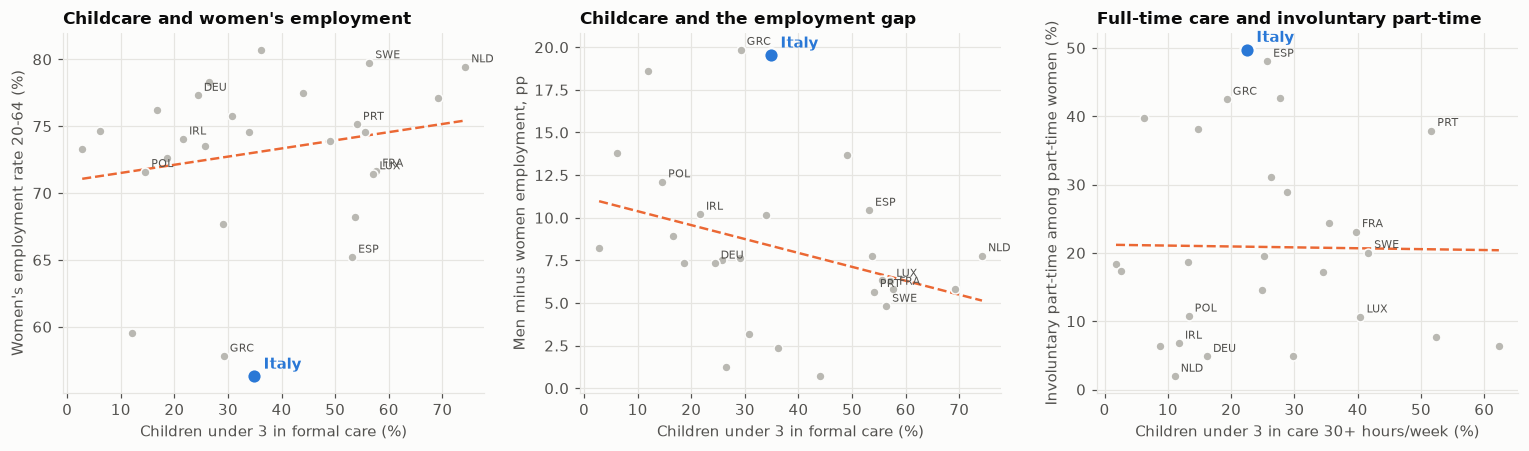

In [2]:
cc = wide(panel, "childcare_under3_30h_plus_pct") + wide(panel, "childcare_under3_1_29h_pct"); fe = wide(panel, "employment_rate_20_64_female"); gap = wide(panel, "employment_rate_20_64_male") - fe
inv = wide(panel, "involuntary_part_time_female_15_64"); W = slice(2022, 2024)
m = lambda w: w.loc[W, [c for c in EU27_ISO3 if c in w]].mean()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
scatter_italy(axes[0], m(cc), m(fe), "Children under 3 in formal care (%)", "Women's employment rate 20-64 (%)", "Childcare and women's employment")
scatter_italy(axes[1], m(cc), m(gap), "Children under 3 in formal care (%)", "Men minus women employment, pp", "Childcare and the employment gap")
scatter_italy(axes[2], m(wide(panel, "childcare_under3_30h_plus_pct")), m(inv), "Children under 3 in care 30+ hours/week (%)", "Involuntary part-time among part-time women (%)", "Full-time care and involuntary part-time")
fig.tight_layout(); save(fig, "18_childcare_scatters")
x, y = m(cc).dropna(), m(fe)
print("Italy: under-3 formal care %.1f%% (median of others %.1f%%, rank %d/%d); 3-to-school-age early education %.1f%% (median %.1f%%)" % (m(cc)[ITALY], m(cc).drop(ITALY).median(), m(cc).rank(ascending=False)[ITALY], m(cc).notna().sum(), m(wide(panel, "ece_participation_3_to_school_pct"))[ITALY], m(wide(panel, "ece_participation_3_to_school_pct")).drop(ITALY).median()))
d = pd.concat([m(cc), m(fe)], axis=1).dropna(); print("corr(childcare, women's employment) across EU27: %.2f" % d.iloc[:, 0].corr(d.iloc[:, 1]))

,Italy,median others,DEU,FRA,ESP,Italy tax+SSC rate,median tax+SSC,Italy family benefit % of gross
"Single, 50% of avg wage",12.0,18.2,28.6,13.9,6.7,12.0,18.7,0.0
"Single, 100%",28.3,27.4,37.3,27.6,22.0,28.3,27.4,0.0
"Single, 167%",39.5,33.8,41.5,33.5,27.8,39.5,33.8,0.0
"Single parent, 2 children, 67%",-0.4,3.7,13.9,-6.8,3.7,19.4,15.4,19.8
"Couple, 2 children, 100%",12.9,16.2,19.5,16.9,15.8,26.2,20.7,13.2


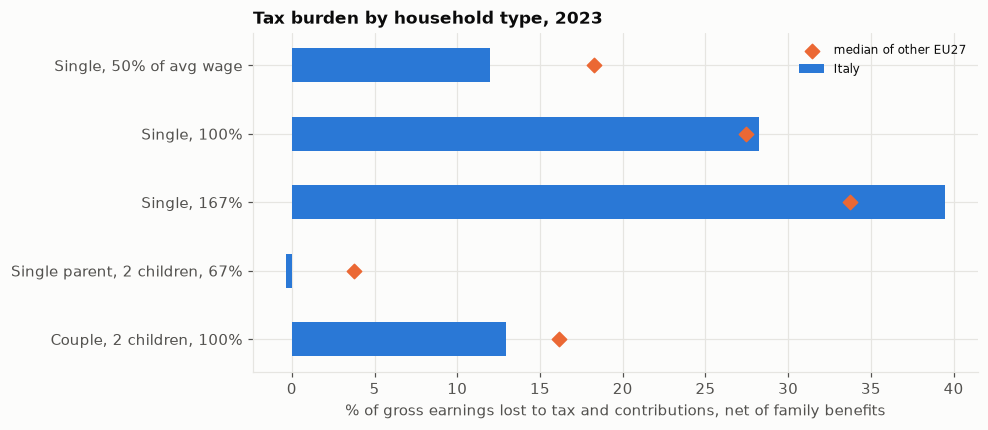

In [3]:
e = pd.read_parquet(PROCESSED / "earnings_cases.parquet"); e = e[e.year == 2023]
t = e.pivot_table(index=["iso3", "ecase"], columns="estruct", values="value")
t["tax_ssc_rate"] = (t.TAX + t.SOC) / t.GRS * 100; t["net_rate"] = (t.GRS - t.NET) / t.GRS * 100  # net_rate also counts family benefits
labels = {"P1_NCH_AW50": "Single, 50% of avg wage", "P1_NCH_AW100": "Single, 100%", "P1_NCH_AW167": "Single, 167%", "P1_CH2_AW67": "Single parent, 2 children, 67%", "CPL_CH2_AW100": "Couple, 2 children, 100%"}
eu = [c for c in EU27_ISO3 if c != ITALY]; rows = {}
for case, lab in labels.items():
    s = t.xs(case, level="ecase"); rows[lab] = {"Italy": s.loc[ITALY, "net_rate"], "median others": s.loc[[c for c in eu if c in s.index], "net_rate"].median(), "DEU": s.loc["DEU", "net_rate"], "FRA": s.loc["FRA", "net_rate"], "ESP": s.loc["ESP", "net_rate"],
                                                "Italy tax+SSC rate": s.loc[ITALY, "tax_ssc_rate"], "median tax+SSC": s.loc[[c for c in eu if c in s.index], "tax_ssc_rate"].median(), "Italy family benefit % of gross": s.loc[ITALY, "FAM"] / s.loc[ITALY, "GRS"] * 100}
res = pd.DataFrame(rows).T; display(res.round(1))
fig, ax = plt.subplots(figsize=(8.5, 4)); yy = np.arange(len(res))
ax.barh(yy, res["Italy"], color=ITALY_C, height=0.5, label="Italy", zorder=2); ax.scatter(res["median others"], yy, color=EU_C, marker="D", s=44, zorder=3, label="median of other EU27")
ax.set_yticks(yy, res.index); ax.invert_yaxis(); ax.set_xlabel("% of gross earnings lost to tax and contributions, net of family benefits"); ax.set_title("Tax burden by household type, 2023"); ax.legend(fontsize=8); save(fig, "18_tax_by_household")

## Takeaways (Eurostat; 2022-2024 averages for childcare, 2023 for tax)
- **Childcare coverage for under-3s is not an outlier:** 34.9% of children under 3 are in formal care (median of the other members 32.4%; 13th of 27) and 93.4% of children from age 3 to school age attend early education (median 94.0%). Across EU27 countries, coverage is only weakly related to women's employment (correlation 0.19). So coverage at national level does not explain Italy's very low female employment; hours, quality, regional gaps (the South), elder care, job availability and norms matter, and this measure cannot separate them.
- **Tax burden is progressive on single earners:** for a single worker the share of earnings paid in tax and contributions is 12.0% at 50% of the average wage (median 18.2%), 28.3% at 100% (27.4%) and 39.5% at 167% (33.8%). Italy taxes low earners lightly and higher earners heavily relative to peers.
- **Families receive large offsets:** family benefits are worth 13.2% of gross earnings for a couple with two children and 19.8% for a single parent at 67% of the average wage, so the net burden (12.9% and -0.4%) is below the medians (16.2% and 3.7%) even though tax and contributions alone (26.2% for the couple vs 20.7%) are higher.
- Caveat: Eurostat's cases are stylised full-year, full-time workers; they say nothing about part-time work or the informal economy.